# Imports


In [1]:
import keras
import datasets
import numpy as np
import pandas as pd
import transformers
import sklearn.metrics
import tensorflow as tf
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt


In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except:
        pass


# Dataset

Load the dataset (we will be using [go_emotions](https://huggingface.co/datasets/google-research-datasets/go_emotions)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset. Implement two datasets: variable and fixed sentence length (in tokens). Don't forget to split the dataset into train and test subsets


In [3]:
dataset = datasets.load_dataset('google-research-datasets/go_emotions', name='raw', split='train')


In [4]:
emotions = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
    'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
    'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]


In [5]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token


In [6]:
df = dataset.to_pandas()
df.columns


Index(['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id',
       'created_utc', 'rater_id', 'example_very_unclear', 'admiration',
       'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion',
       'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust',
       'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy',
       'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
       'remorse', 'sadness', 'surprise', 'neutral'],
      dtype='str')

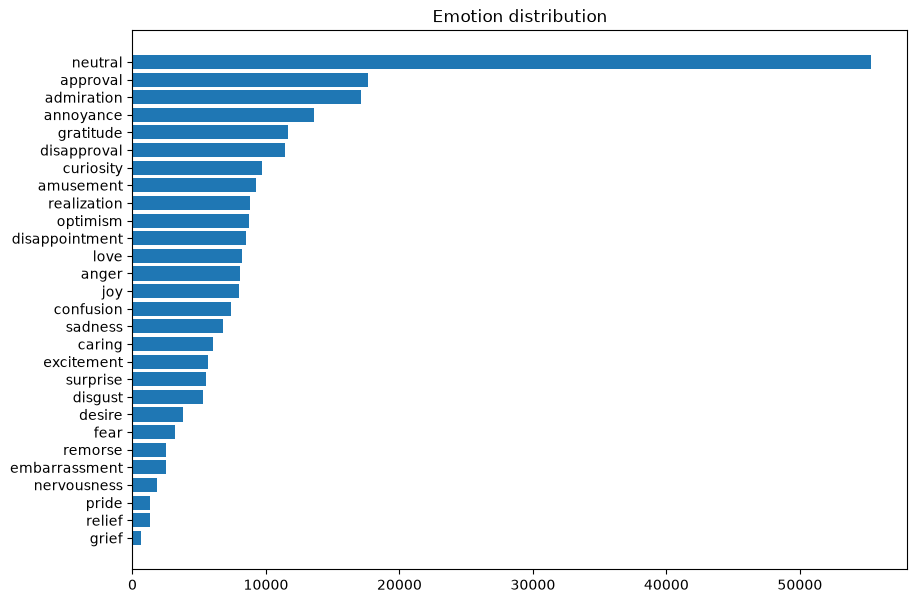

In [7]:
# распределение эмоций
counts = df[emotions].sum().sort_values()

plt.figure(figsize=(10, 7))
plt.barh(counts.index, counts.values)
plt.title('Emotion distribution')
plt.show()


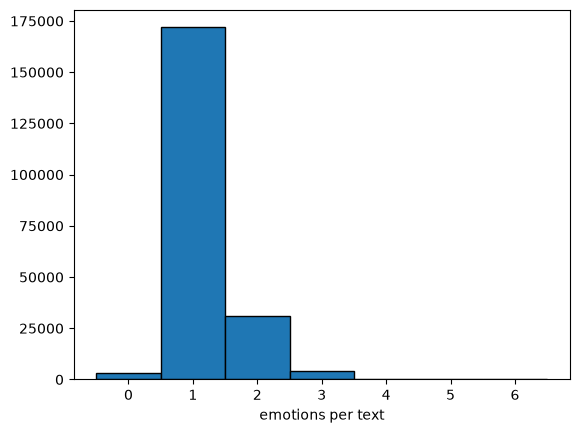

In [8]:
# сколько эмоций на один текст
plt.hist(df[emotions].sum(axis=1), bins=np.arange(0, 8) - 0.5, edgecolor='black')
plt.xlabel('emotions per text')
plt.show()


In [9]:
# длины текстов в токенах
lens = [len(tokenizer.encode(t)) for t in tqdm.tqdm(df['text'])]

print('max:', np.max(lens))
print('mean:', np.mean(lens).round(2))
print('median:', np.median(lens))
print('95%:', np.percentile(lens, 95))
print('99%:', np.percentile(lens, 99))
print('99.9%:', np.percentile(lens, 99.9))


max: 1435
mean: 17.11
median: 17.0
95%: 31.0
99%: 35.0
99.9%: 44.0


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1435 > 1024). Running this sequence through the model will result in indexing errors


In [10]:
# 99.9% текстов короче 45 токенов, берём MAX_LENGTH = 44
MAX_LENGTH = 44
BATCH_SIZE = 128

# паддинг нулями, чтобы embedding мог маскировать его через mask_zero
PAD = 0


In [11]:
X = df['text'].to_numpy()
y = df[emotions].to_numpy().astype('float32')

X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(
    X, y, test_size=0.2, random_state=42
)
len(X_train), len(X_test)


(168980, 42245)

In [12]:
# датасет с фиксированной длиной: всё приводим к 44 токенам
enc = tokenizer(X_train.tolist(), truncation=True, padding='max_length',
                max_length=MAX_LENGTH, return_tensors='np')
X_train_fixed = enc['input_ids'].astype('int32')
X_train_fixed[enc['attention_mask'] == 0] = PAD

enc = tokenizer(X_test.tolist(), truncation=True, padding='max_length',
                max_length=MAX_LENGTH, return_tensors='np')
X_test_fixed = enc['input_ids'].astype('int32')
X_test_fixed[enc['attention_mask'] == 0] = PAD

train_fixed = tf.data.Dataset.from_tensor_slices((X_train_fixed, y_train)) \
    .shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_fixed = tf.data.Dataset.from_tensor_slices((X_test_fixed, y_test)) \
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [13]:
# датасет с переменной длиной: паддинг до самого длинного в батче
def encode(texts):
    enc = tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH)
    return [np.array(ids, dtype='int32') for ids in enc['input_ids']]

X_train_var = encode(X_train)
X_test_var = encode(X_test)

def gen(X, y):
    for ids, lab in zip(X, y):
        yield ids, lab

sig = (
    tf.TensorSpec(shape=(None,), dtype=tf.int32),
    tf.TensorSpec(shape=(len(emotions),), dtype=tf.float32),
)

train_var = tf.data.Dataset.from_generator(lambda: gen(X_train_var, y_train), output_signature=sig) \
    .shuffle(10000) \
    .padded_batch(BATCH_SIZE, padded_shapes=([None], [len(emotions)]),
                  padding_values=(tf.constant(PAD, tf.int32), tf.constant(0.0))) \
    .prefetch(tf.data.AUTOTUNE)

test_var = tf.data.Dataset.from_generator(lambda: gen(X_test_var, y_test), output_signature=sig) \
    .padded_batch(BATCH_SIZE, padded_shapes=([None], [len(emotions)]),
                  padding_values=(tf.constant(PAD, tf.int32), tf.constant(0.0))) \
    .prefetch(tf.data.AUTOTUNE)


In [14]:
x_b, y_b = next(iter(train_fixed))
print('fixed:', x_b.shape, y_b.shape)

x_b, y_b = next(iter(train_var))
print('variable:', x_b.shape, y_b.shape)


fixed: (128, 44) (128, 28)
variable: (128, 44) (128, 28)


# Model

Implement your model. The model should have the RNN architecture (with LSTM or GRU cells), support stacking and bidirectional feature extraction.


In [15]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None


In [16]:
def get_model(
    units: int,
    n_tokens: int,
    n_labels: int,
    n_stacks: int = 1,
    bidirectional: bool = False,
    name: str | None = None,
    cell_type: type[keras.layers.Layer] = keras.layers.LSTMCell
) -> keras.Model:
    inputs = keras.Input(shape=(None,), dtype='int32')
    x = keras.layers.Embedding(n_tokens, 64, mask_zero=True)(inputs)
    for i in range(n_stacks):
        rnn = keras.layers.RNN(cell_type(units), return_sequences=(i < n_stacks - 1))
        if bidirectional:
            rnn = keras.layers.Bidirectional(rnn)
        x = rnn(x)
    x = keras.layers.Dropout(0.3)(x)
    outputs = keras.layers.Dense(n_labels, activation='sigmoid')(x)
    return keras.Model(inputs, outputs, name=name)


In [17]:
m = get_model(64, len(tokenizer.get_vocab()), len(emotions), n_stacks=2, bidirectional=True)
m.summary()


Model: "functional"
┌─────────────────────┬───────────────────┬────────────┬───────────────────┐
│ Layer (type)        │ Output Shape      │    Param # │ Connected to      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer         │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 64)  │  3,216,448 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, None, 128) │     66,048 │

# Training

Train several models on the two dataset variants. Use either of the cell types (LSTM or GRU)
* Simple RNN (no stacking, one direction)
* Stacked RNN (stacking, one direction)
* Bidirectional RNN (no stacking, bidirectional)
* Stacked Bidirectional RNN (stacking, bidirectional)

Which loss should be used to multilabel classification? Which metrics?

Текст может иметь несколько эмоций сразу, поэтому берём binary_crossentropy. Метрики — ROC AUC и F1, классы сильно несбалансированы, так что на accuracy смотреть смысла нет.


In [18]:
model_configs = [
    {'name': 'simple',       'n_stacks': 1, 'bidirectional': False},
    {'name': 'stacked',      'n_stacks': 2, 'bidirectional': False},
    {'name': 'bidi',         'n_stacks': 1, 'bidirectional': True},
    {'name': 'stacked_bidi', 'n_stacks': 2, 'bidirectional': True},
]

loader_types = ['fixed', 'variable']
loaders = {'fixed': (train_fixed, test_fixed), 'variable': (train_var, test_var)}

UNITS = 64
EPOCHS = 4


In [19]:
histories = {}
models = {}

for loader_type in loader_types:
    tr, te = loaders[loader_type]
    for cfg in tqdm.tqdm(model_configs, desc=loader_type):
        name = f"{cfg['name']}_{loader_type}"
        model = get_model(
            UNITS, len(tokenizer.get_vocab()), len(emotions),
            n_stacks=cfg['n_stacks'],
            bidirectional=cfg['bidirectional'],
            name=name,
            cell_type=keras.layers.LSTMCell,
        )
        model.compile(
            loss='binary_crossentropy',
            optimizer=keras.optimizers.Adam(1e-3),
            metrics=[keras.metrics.AUC(multi_label=True, num_labels=len(emotions), name='auc')],
        )
        histories[name] = model.fit(tr, validation_data=te, epochs=EPOCHS)
        models[name] = model


100%|████████| 4/4

Epoch 1/4
1321/1321 ━━━━ 59s 45ms/step - auc: 0.5137 - loss: 0.1704 - val_auc: 0.5594 - val_loss: 0.1541
Epoch 2/4
1321/1321 ━━━━ 59s 45ms/step - auc: 0.6158 - loss: 0.1499 - val_auc: 0.7061 - val_loss: 0.1388
Epoch 3/4
1321/1321 ━━━━ 59s 45ms/step - auc: 0.7344 - loss: 0.1353 - val_auc: 0.7698 - val_loss: 0.1314
Epoch 4/4
1321/1321 ━━━━ 59s 45ms/step - auc: 0.7873 - loss: 0.1279 - val_auc: 0.7868 - val_loss: 0.1272
Epoch 1/4
1321/1321 ━━━━ 92s 70ms/step - auc: 0.5019 - loss: 0.1708 - val_auc: 0.5405 - val_loss: 0.1563
Epoch 2/4
1321/1321 ━━━━ 92s 70ms/step - auc: 0.6095 - loss: 0.1516 - val_auc: 0.7138 - val_loss: 0.1385
Epoch 3/4
1321/1321 ━━━━ 92s 70ms/step - auc: 0.7373 - loss: 0.1352 - val_auc: 0.7683 - val_loss: 0.1300
Epoch 4/4
1321/1321 ━━━━ 92s 70ms/step - auc: 0.7856 - loss: 0.1275 - val_auc: 0.7916 - val_loss: 0.1263
Epoch 1/4
1321/1321 ━━━━ 75s 57ms/step - auc: 0.5658 - loss: 0.1638 - val_auc: 0.6809 - val_loss: 0.1427
Epoch 2/4
1321/1321 ━━━━ 75s 57ms/step - auc: 0.7128 - 

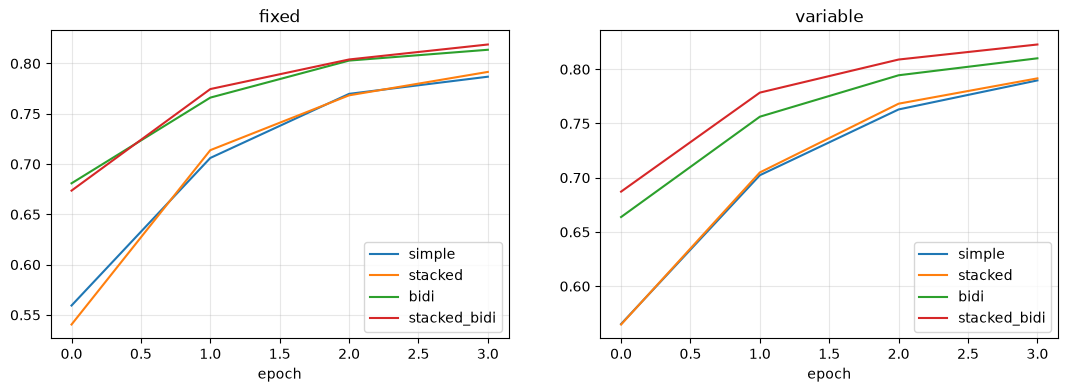

In [20]:
# кривые обучения
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, loader_type in zip(axes, loader_types):
    for cfg in model_configs:
        name = f"{cfg['name']}_{loader_type}"
        ax.plot(histories[name].history['val_auc'], label=cfg['name'])
    ax.set_title(loader_type)
    ax.set_xlabel('epoch')
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()


# Evaluation

Evaluate the models you trained on the test datasets. Plot ROC curves for each label (use `sklearn.metrics.RocCurveDisplay`) for each model.


In [21]:
def calculate_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        'auc': sklearn.metrics.roc_auc_score(y_true, y_prob, average='macro'),
        'f1_macro': sklearn.metrics.f1_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_micro': sklearn.metrics.f1_score(y_true, y_pred, average='micro', zero_division=0),
    }


In [22]:
def plot_roc_curve(X, y, model, ax=None):
    '''Plots ROC curves for each of the labels (on a single axes) and outputs mean ROC AUC score.'''
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
    y_prob = model.predict(X, verbose=0)
    aucs = []
    for i, emo in enumerate(emotions):
        if y[:, i].sum() == 0:
            continue
        d = sklearn.metrics.RocCurveDisplay.from_predictions(y[:, i], y_prob[:, i], name=emo, ax=ax)
        aucs.append(d.roc_auc)
    ax.plot([0, 1], [0, 1], '--', color='black', label='random')
    mean_auc = np.mean(aucs)
    ax.set_title(f'{model.name} | mean ROC AUC: {mean_auc:.4f}')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    return mean_auc, y_prob


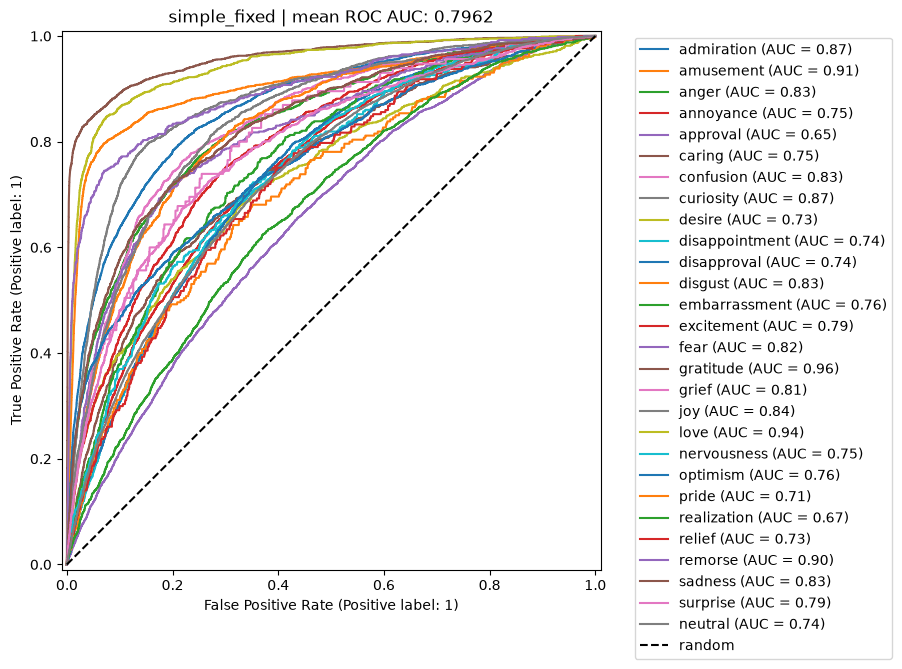

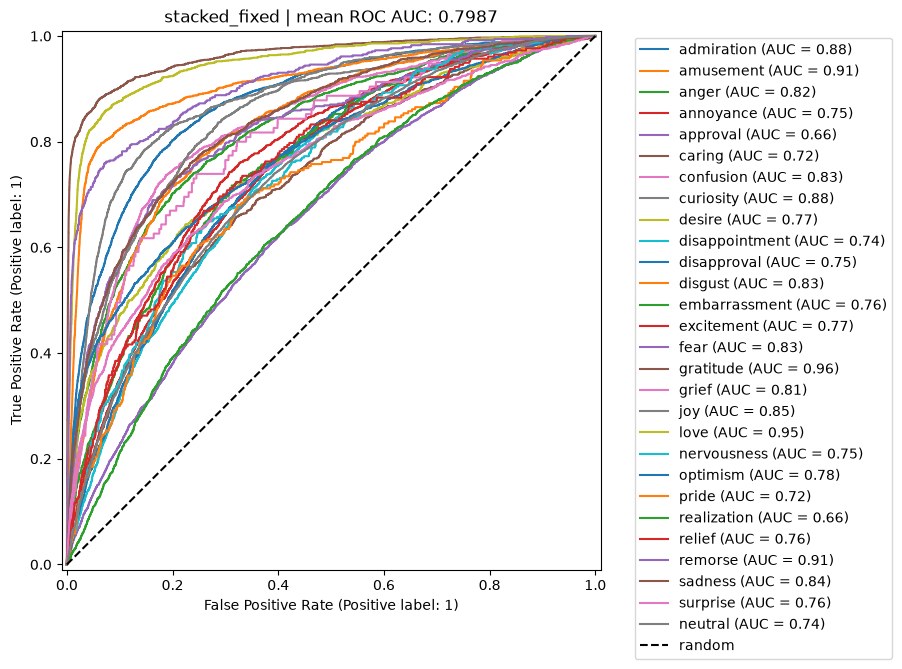

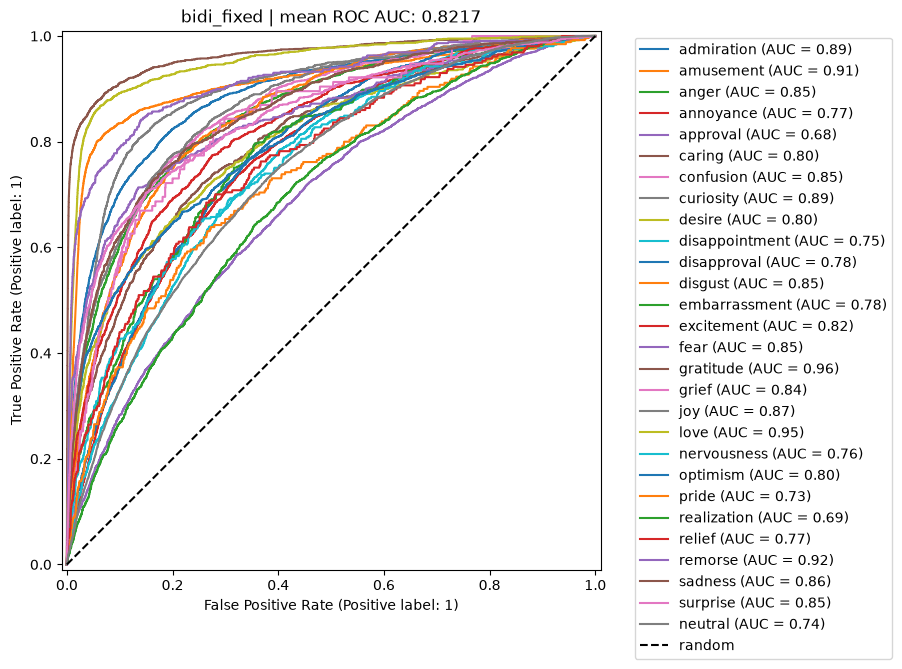

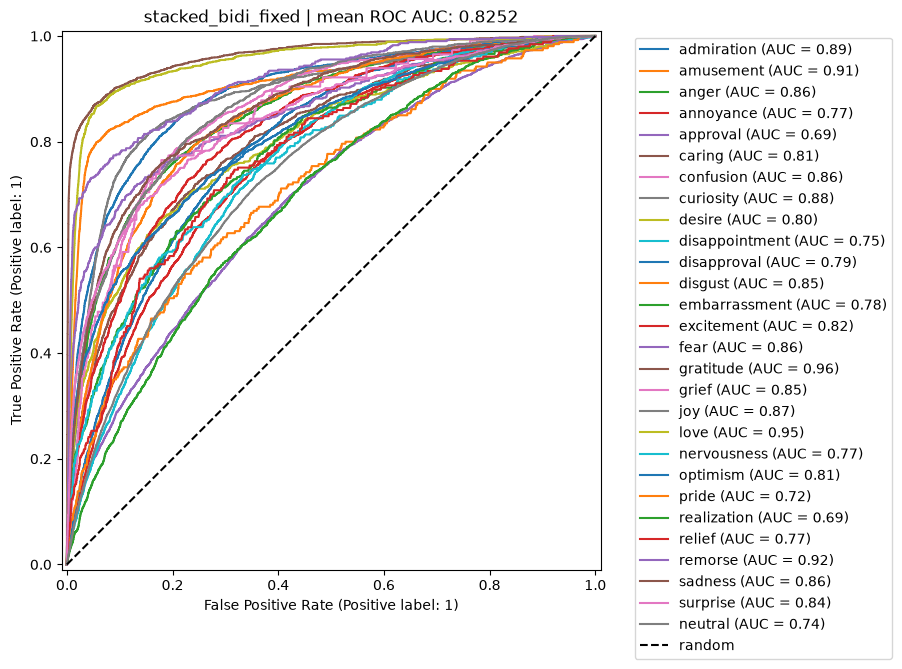

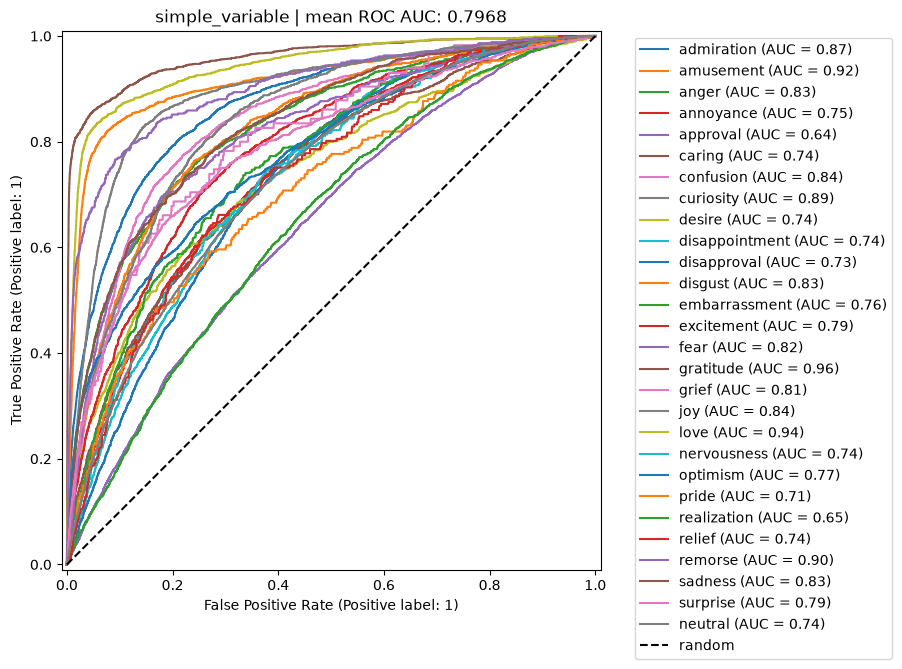

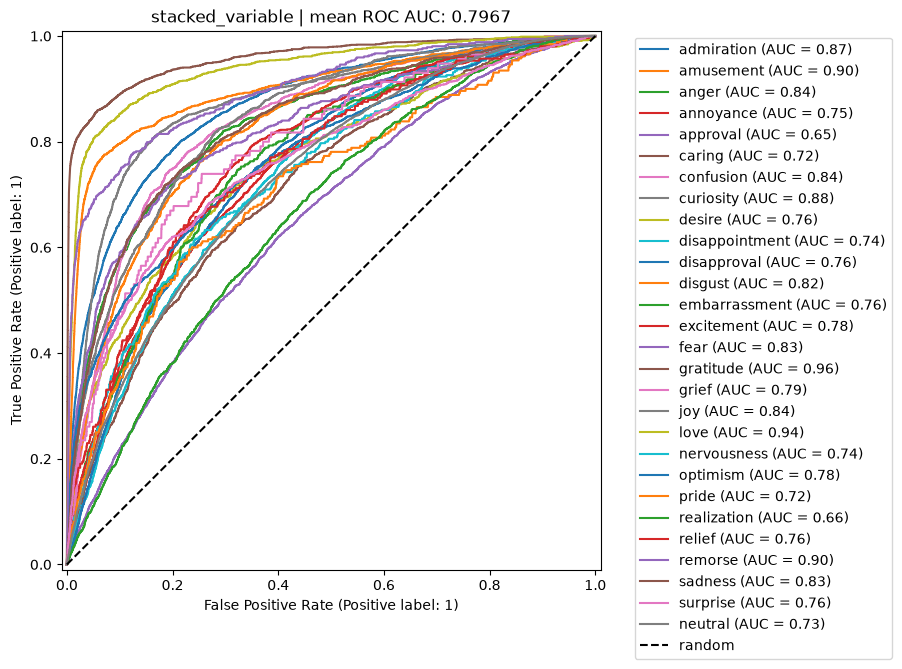

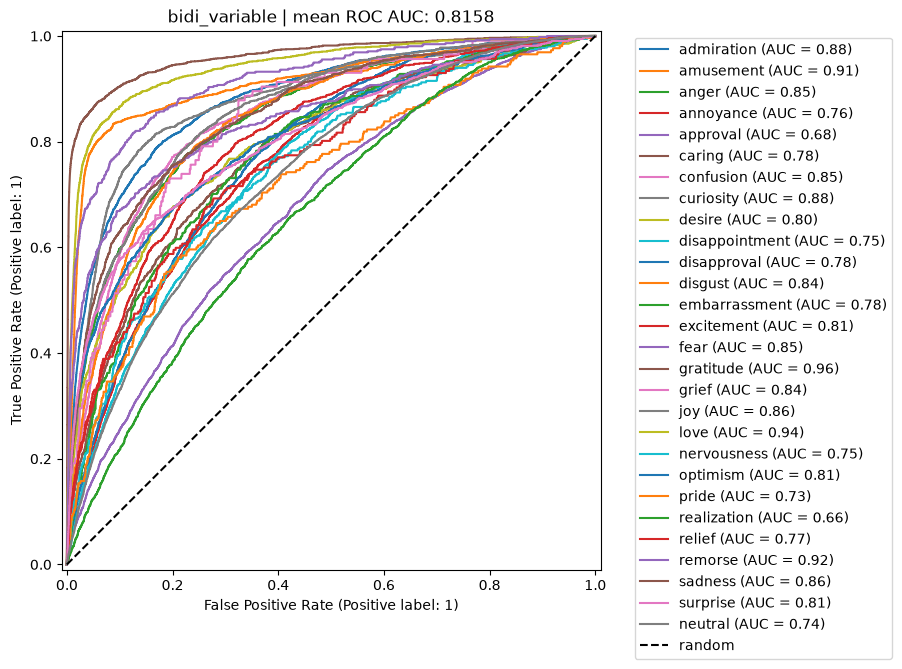

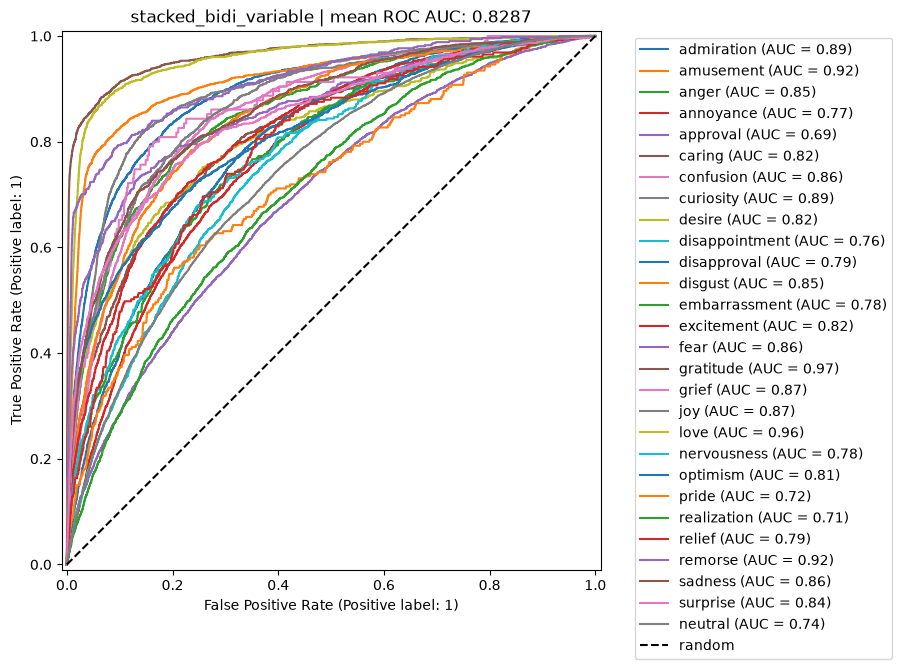

In [23]:
predictions = {}
for loader_type in loader_types:
    te = loaders[loader_type][1]
    for cfg in model_configs:
        name = f"{cfg['name']}_{loader_type}"
        fig, ax = plt.subplots(figsize=(12, 7))
        mean_auc, y_prob = plot_roc_curve(te, y_test, models[name], ax=ax)
        predictions[name] = y_prob
        plt.tight_layout()
        plt.show()


Plot the mean ROC AUC scores. Which model has the highest score? On what kind of dataset?


In [24]:
results = pd.DataFrame([
    {'model': name, **calculate_metrics(y_test, predictions[name])}
    for name in predictions
]).sort_values('auc', ascending=False).reset_index(drop=True)
results


                   model       auc  f1_macro  f1_micro
0  stacked_bidi_variable  0.828732  0.137266  0.289195
1     stacked_bidi_fixed  0.825177  0.137297  0.282454
2             bidi_fixed  0.821741  0.120097  0.265538
3          bidi_variable  0.815838  0.122805  0.257452
4          stacked_fixed  0.798720  0.097441  0.250585
5        simple_variable  0.796849  0.089691  0.229036
6       stacked_variable  0.796684  0.091591  0.219809
7           simple_fixed  0.796240  0.089807  0.231106

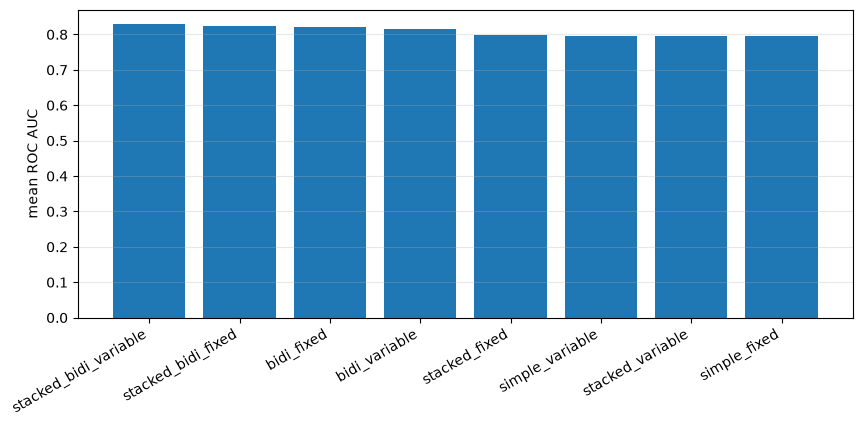

In [25]:
plt.figure(figsize=(10, 4))
plt.bar(results['model'], results['auc'])
plt.xticks(rotation=30, ha='right')
plt.ylabel('mean ROC AUC')
plt.grid(axis='y', alpha=0.3)
plt.show()


Лучший результат у stacked_bidi на variable-датасете, AUC около 0.83: основной прирост даёт двунаправленность, стек добавляет ещё немного. Variable чуть лучше fixed — модель не тратится на паддинг. F1 низкий из-за порога 0.5 и сильного дисбаланса редких эмоций.


Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?


In [26]:
def label_text(text, model, threshold=0.5, max_length=None):
    ids = tokenizer.encode(text, truncation=True, max_length=max_length)
    proba = model.predict(np.array([ids]), verbose=0)[0]
    return [emo for emo, p in zip(emotions, proba) if p >= threshold]

def plot_emotion_scores(text, model, max_length=None, ax=None):
    ids = tokenizer.encode(text, truncation=True, max_length=max_length)
    proba = model.predict(np.array([ids]), verbose=0)[0]
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 7))
    idx = np.argsort(proba)
    ax.barh(np.array(emotions)[idx], proba[idx], edgecolor='black')
    ax.set_xlim(0, 1)
    ax.set_xlabel('probability')
    ax.set_title(text)
    plt.tight_layout()
    return proba


For each of your texts get a list of emotion labels and plot emotion scores


In [27]:
texts = [
    'I am so happy that everything worked out!',
    'I cannot believe you did this to me.',
    'Thank you so much for helping me.',
    'I am really worried about what happens next.',
    'That was absolutely hilarious!',
]


In [28]:
best_name = results.iloc[0]['model']
best_model = models[best_name]
best_name


'stacked_bidi_variable'

Text: I am so happy that everything worked out!
Predicted: ['joy']


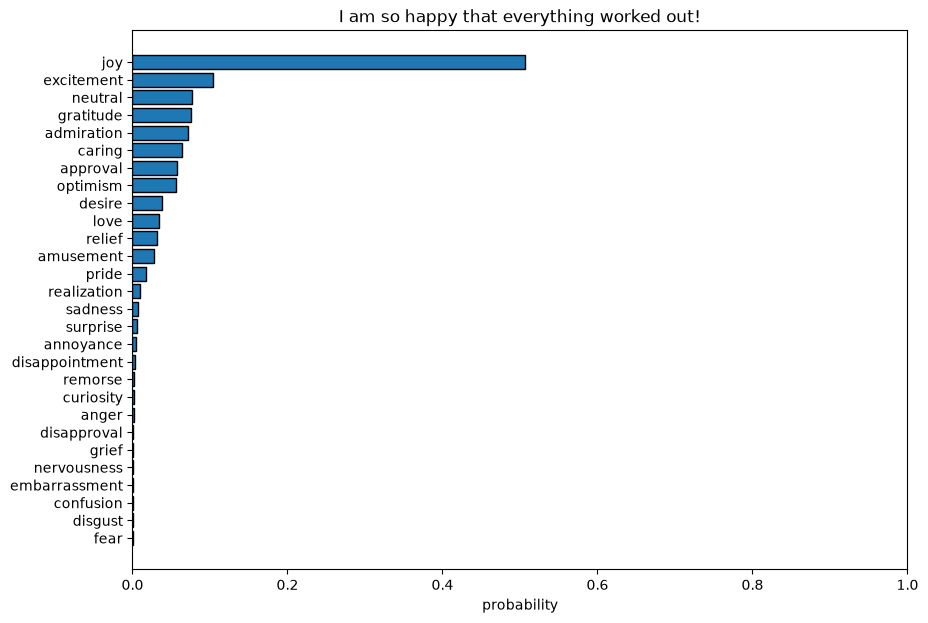

Text: I cannot believe you did this to me.
Predicted: []


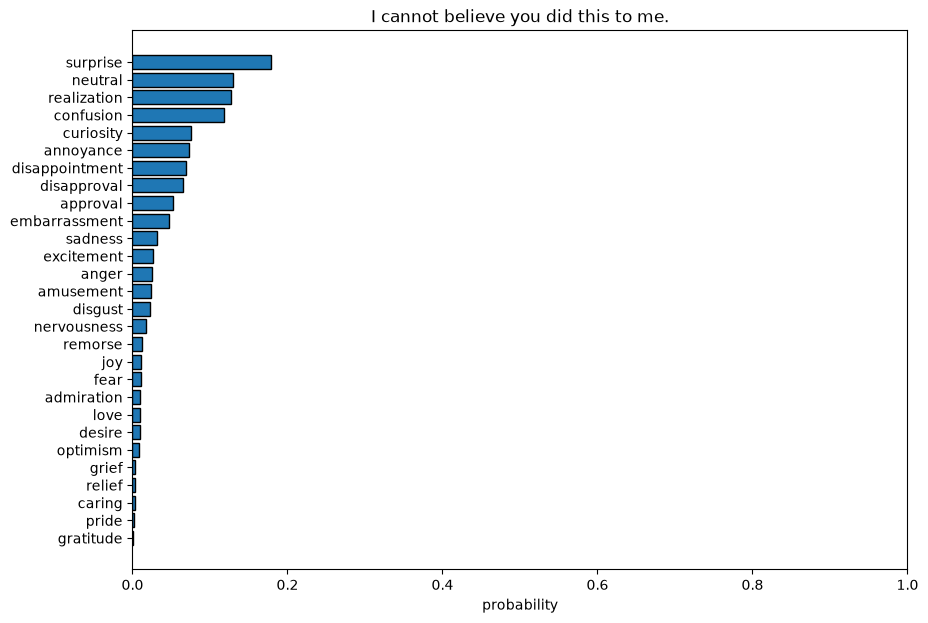

Text: Thank you so much for helping me.
Predicted: ['gratitude']


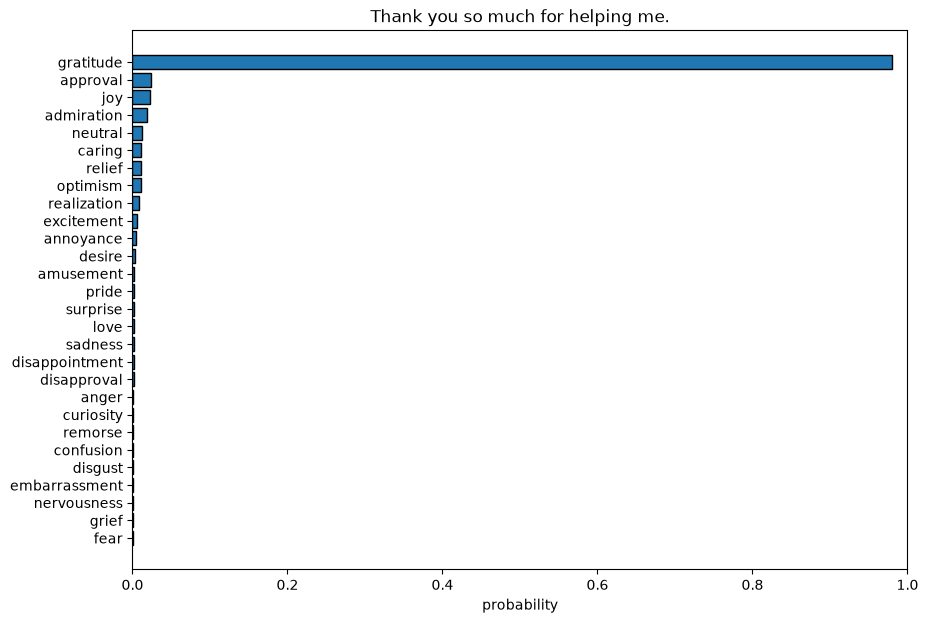

Text: I am really worried about what happens next.
Predicted: []


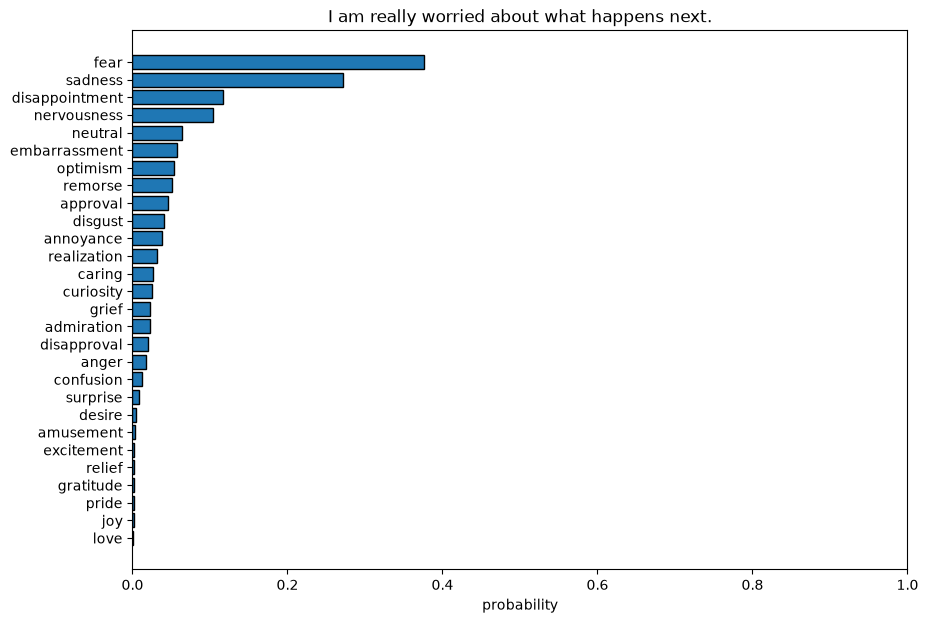

Text: That was absolutely hilarious!
Predicted: ['amusement']


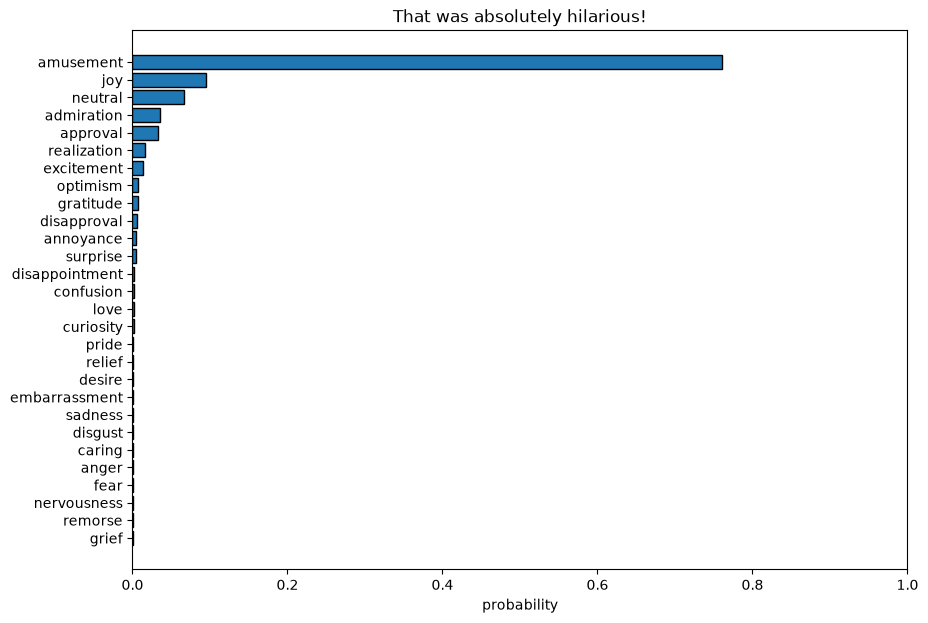

In [29]:
for text in texts:
    print('Text:', text)
    print('Predicted:', label_text(text, best_model, max_length=MAX_LENGTH))
    plot_emotion_scores(text, best_model, max_length=MAX_LENGTH)
    plt.show()


В целом предсказания осмысленные: радостным текстам — joy/excitement, благодарности — gratitude, смешному — amusement. Но иногда модель вообще не ловит эмоцию и выдаёт пустой список или neutral — видимо, 4 эпох маловато.


# Bonus

Train and evaluate the same model as your best one, but use a different cell type

(не делал)
